# Motional Wigner functions at weak dephasing

Compare the unsqueezed $|1\rangle$ and $|2\rangle$ preparations after a real displacement signal $\beta=1$ and before the $\alpha$ readout. Each snapshot is a separate run at the same pulse duration and equal integrated heating and cooling $G_h=G_c=0.01$. The first figure resolves $0\leq G_\phi=\Gamma_\phi t_{\rm sig}\leq1$. The second gives three reference points extending to strong dephasing.

This uses the normalized-time signal and jump operators from [1121](1121_dephasing_reentrance.ipynb) in the QuantumOptics master-equation solver. The Wigner section in that notebook uses $G_h=G_c=0.003$. Here the bath matches the earlier $n=1$ to $n=2$ sensing crossover near 29.60. A white cross marks the origin, an open circle marks the density-matrix centroid, and a black contour traces zero. The colors saturate at ±0.2 in every panel.

In [1]:
import Pkg
Pkg.activate(@__DIR__)
using PyPlot

  Activating project at `~/projects/TestSQRLab`


In [2]:
using LinearAlgebra
import QuantumOptics as QO

weak_G = [0., 0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.75, 0.90, 1.]
context_G = [4., 29.60, 100.]
focks = [1, 2]
beta = 1.0
bath = 0.01
b = QO.FockBasis(29)  # 30 motional levels, starting at |0>
a = QO.destroy(b)
num = QO.number(b)
H = im * beta * (QO.dagger(a) - a)
X = (a + QO.dagger(a)) / sqrt(2)
quad = collect(-4.:0.1:4.)
function snapshot(n, g)
    jumps = [sqrt(bath)*a, sqrt(bath)*QO.dagger(a), sqrt(g)*num]
    initial = QO.dm(QO.fockstate(b, n))
    _, states = QO.timeevolution.master([0.,1.], initial, H, jumps;
                                        reltol=1e-9, abstol=1e-12)
    rho = last(states)
    center = real(QO.expect(X, rho))
    expected = sqrt(2)*beta*(iszero(g) ? 1.0 : -2*expm1(-g/2)/g)
    @assert abs(center-expected) < 1e-7
    @assert abs(tr(rho)-1) < 1e-8 && abs(sum(diag(rho.data)[end-4:end])) < 1e-8
    return (W=QO.wigner(rho, quad, quad), center=center)
end
snapshots = Dict((n,g) => snapshot(n,g) for n in focks for g in vcat(weak_G,context_G));

In [3]:
function wigner_sheet(values, cols)
    blocks = cld(length(values), cols)
    fig, axes = subplots(2blocks, cols, squeeze=false, sharex=true, sharey=true,
                         figsize=(2cols+1.1, 2.05*(2blocks)+1), constrained_layout=true)
    image = nothing
    for (i,n) in enumerate(focks), (j,g) in enumerate(values)
        row = (i-1)*blocks + cld(j,cols)
        col = mod1(j,cols)
        ax = axes[row,col]
        s = snapshots[n,g]
        image = ax.pcolormesh(quad,quad,permutedims(s.W),cmap="RdBu_r",
                              vmin=-0.2,vmax=0.2,shading="nearest")
        ax.contour(quad,quad,permutedims(s.W),levels=[0.],colors="#555555",linewidths=0.6)
        ax.plot(0,0,"w+",ms=7)
        ax.plot(s.center,0,"o",mfc="none",mec="black",ms=6)
        ax.set(aspect="equal",title="Γφt = $g",xticks=[-3,0,3],yticks=[-3,0,3])
        col == 1 && ax.set_ylabel("|$n⟩   p")
        row == 2blocks && ax.set_xlabel("x")
    end
    fig.colorbar(image,ax=vec(axes),label="W(x,p)",extend="both",shrink=0.75)
    fig.suptitle("Motional Wigner function before readout\nβ = 1,  Gₕ = Gc = 0.01     + origin    ○ centroid")
    return fig
end

wigner_sheet (generic function with 1 method)

## Weak dephasing

Read each pair of rows left to right for one preparation. The zero-dephasing column includes the complete drive and balanced bath.

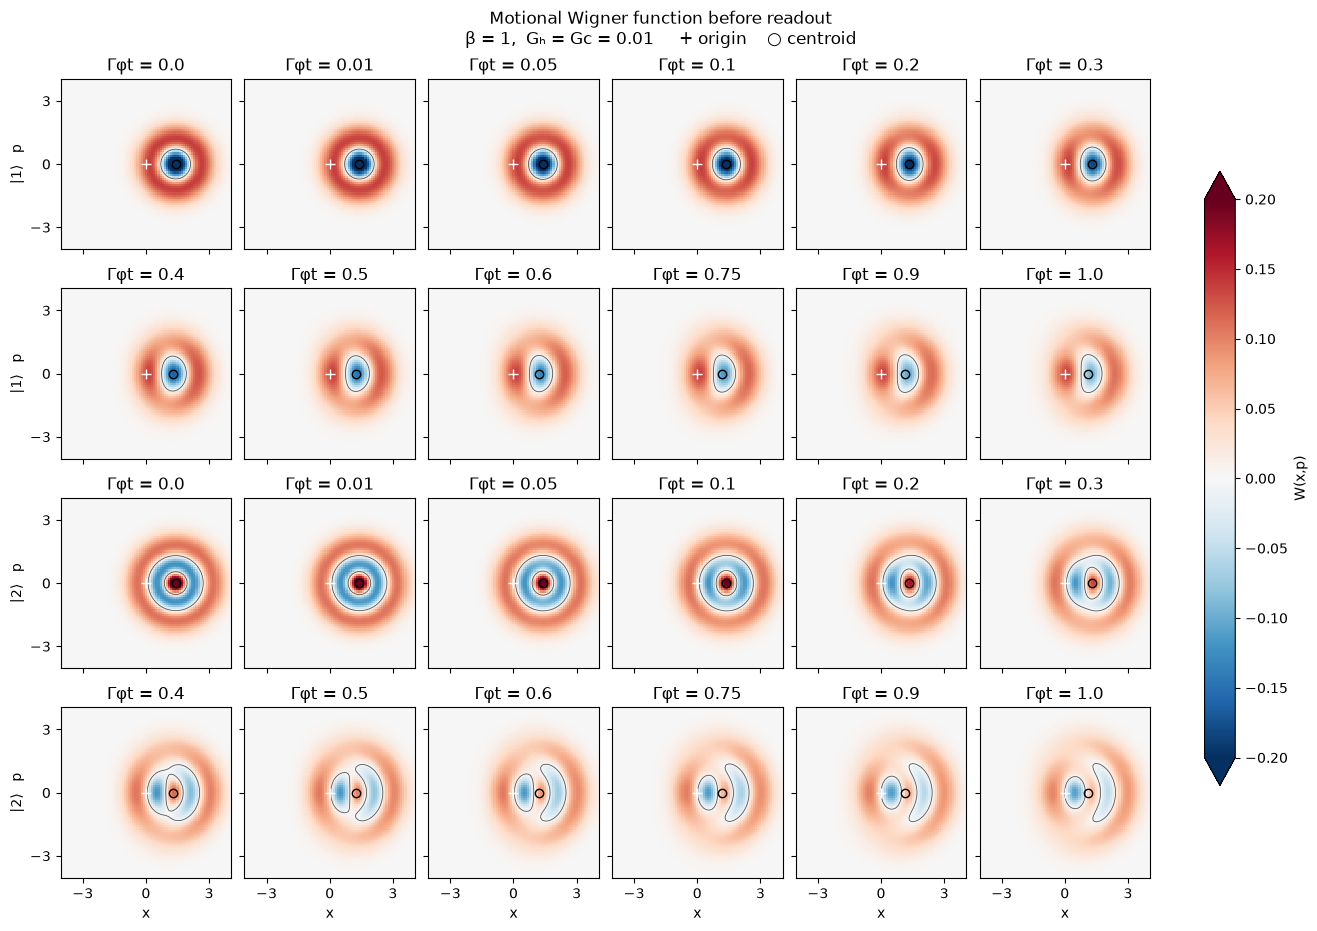

In [4]:
fig = wigner_sheet(weak_G, 6)
display(fig)
close(fig);

## Larger dephasing

The middle reference is the previously calculated sensing crossover for this bath. The snapshots here compare motional states at that point.

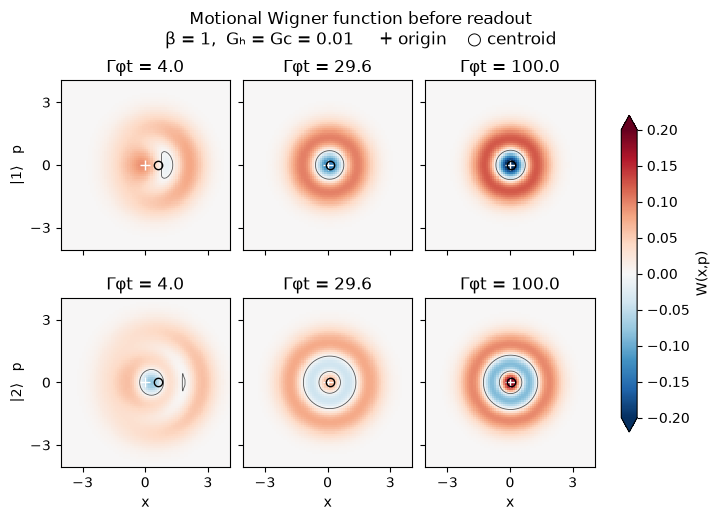

In [5]:
fig = wigner_sheet(context_G, 3)
display(fig)
close(fig);

## Reading the weak sweep

The centroid moves from x = 1.414 at zero dephasing to 1.251 at $G_\phi=0.5$ and 1.113 at $G_\phi=1$. Both preparations have the same centroid trajectory. The negative disk and annulus respond differently to the noise. The simulation checks the centroid against the balanced-bath first-moment solution at every point.

## Connecting the Wigner snapshots to the winning state

The original [1121 phase diagram and Wigner snapshots](1121_dephasing_reentrance.ipynb) connect two observables. The Wigner function describes the motional state before readout. The optimized variance bound $Q_n$ uses its derivative with respect to the signal and predicts which preparation gives the greatest sensitivity. The denser weak sweep above shows how the rings change shape between 0 and 1. Its two example states alone cannot establish the global winner.

Here we repeat P7's $\beta=1$, $h=G_h=G_c=0.003$ cut, then repeat the ranking at $h=0.01$ to match the fine sweep. We compare all six unsqueezed Fock states $n=0,\ldots,5$. P7’s map includes all six, while its snapshot captions rank the five displayed states. We use one color scale across every Wigner panel to make changes in amplitude comparable.

The next cell reuses the drive, signal derivative and qubit readout from 1121. The calculation uses 30 motional levels, twice the default number of time steps and an independent readout optimization over $\alpha=0.05,0.055,\ldots,3.2$ for each state. We identify the first upward switch in the sampled optimum and bisect the difference between the best bounds on either side of that Fock number. Each printed bracket gives the numerical search tolerance for these settings.

In [ ]:
using Printf
BLAS.set_num_threads(1)
function displace_matrix(ξ::Number, d::Int; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (r > 0 improves sensitivity, eq. 33)
function squeezed_fock(n::Int, r::Real, d::Int; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact dephasing + cooling + heating map over a fraction `frac` of the exposure, one small matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}
    diagonal_only::Bool
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive. Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs, d::Int) = [displace_matrix(2im * a, d) for a in αs]



In [ ]:
rank_ns = 0:5
rank_h = [0.003,0.01]
rank_g = sort(unique(vcat(weak_G, 10 .^ range(0,log10(300.),length=45), [4.,300.])))
rank_d = 30
rank_Vs = readout_matrices(collect(0.05:0.005:3.2),rank_d)
rank_psis = [squeezed_fock(n,0.,rank_d) for n in rank_ns]
function rank_states(g,h)
    drv = Drive(1.,g,h,h; d=rank_d,steps=2default_steps(g,h,h))
    cache = [propagate(psi,drv) for psi in rank_psis]
    @assert all(abs(sum(diag(rho)[end-4:end])) < 1e-8 for (rho,_) in cache)
    qs = [minimum(qcrb_from_state(rho,drho,V) for V in rank_Vs) for (rho,drho) in cache]
    return (q=qs,rho=first.(cache))
end
rank_q = [rank_states(g,h).q for g in rank_g, h in rank_h]
function first_upward(ih)
    wins = argmin.(rank_q[:,ih])
    k = findfirst(>(0),diff(wins))
    isnothing(k) && error("No return bracket on sampled cut")
    split = wins[k]
    lo,hi = rank_g[k:k+1]
    while hi-lo > 0.002
        mid = (hi+lo)/2
        q = rank_states(mid,rank_h[ih]).q
        if minimum(q[split+1:end]) < minimum(q[1:split])
            hi = mid
        else
            lo = mid
        end
    end
    return (lo=lo,hi=hi,left=argmin(rank_states(lo,rank_h[ih]).q)-1,
                       right=argmin(rank_states(hi,rank_h[ih]).q)-1)
end
rank_roots = first_upward.(eachindex(rank_h))
for (h,r) in zip(rank_h,rank_roots)
    println("h = $h   n = $(r.left) → $(r.right)   Gφ in [$(round(r.lo,digits=4)), $(round(r.hi,digits=4))]")
end


h = 0.003   n = 1 → 2   Gφ in [27.5864, 27.5882]
h = 0.01   n = 1 → 2   Gφ in [29.5999, 29.6018]


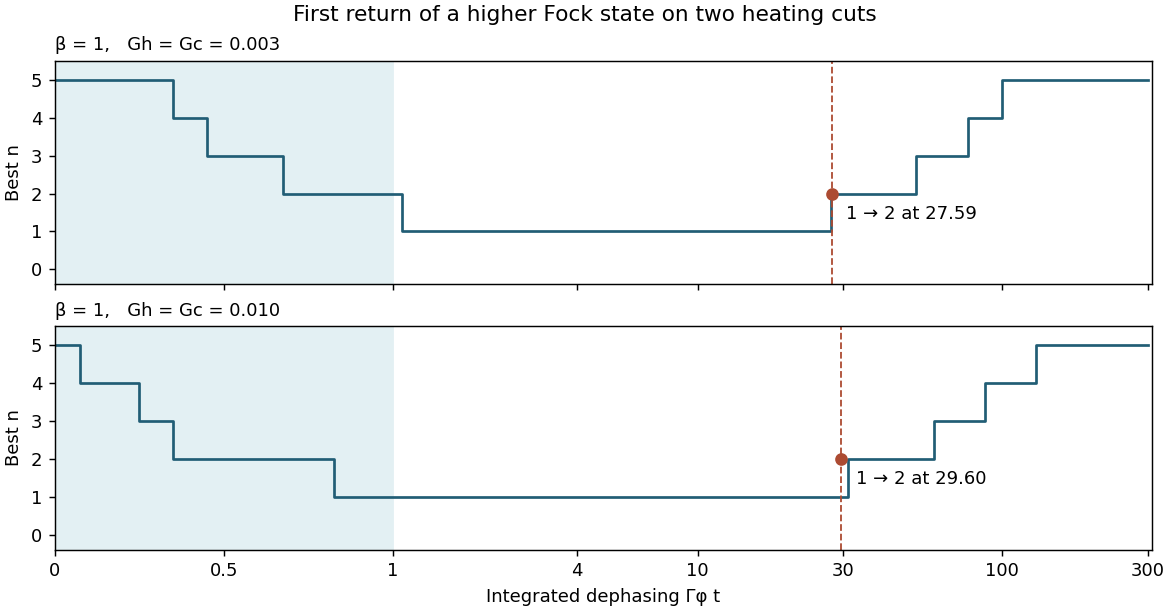

In [ ]:
function return_cuts()
    fig, axes = subplots(2,1,sharex=true,figsize=(9,4.7),constrained_layout=true)
    for (i,h) in enumerate(rank_h)
        ax = axes[i]
        ax.step(rank_g,argmin.(rank_q[:,i]).-1,where="mid",color="#215d75")
        r = rank_roots[i]
        cross = (r.lo+r.hi)/2
        ax.axvline(cross,ls="--",lw=1,color="#ac4b32")
        ax.plot(cross,r.right,"o",color="#ac4b32")
        ax.annotate(@sprintf("%d → %d at %.2f",r.left,r.right,cross),
                    (cross,r.right),xytext=(8,-14),textcoords="offset points")
        ax.axvspan(0,1,color="#e3f0f3",zorder=-1)
        ax.set_xscale("symlog",linthresh=1)
        ax.set(xlim=(0,310),ylim=(-.4,5.5),yticks=0:5,ylabel="Best n")
        ax.set_title(@sprintf("β = 1,   Gh = Gc = %.3f",h),loc="left",fontsize=10)
    end
    axes[end].set_xticks([0,.5,1,4,10,30,100,300],labels=["0","0.5","1","4","10","30","100","300"])
    axes[end].set_xlabel("Integrated dephasing Γφ t")
    fig.suptitle("First return of a higher Fock state on two heating cuts")
    fig
end
phase_figure = return_cuts()
display(phase_figure)
close(phase_figure);


### Preparations, dephasing and rank at the P7 bath setting

Columns are $n=0,\ldots,5$, from left to right. Rows show the prepared states, a weak reference, a point inside the fine sweep, the low-number regime, the first upward crossover and the strong-dephasing reference. Each evolved panel gives the optimized $Q_n$, its rank and integrated Wigner negativity $N=\int \max(-W,0)\,dx\,dp$. We integrate on $[-6,6]^2$ and display $[-4,4]^2$. Both crossing states are marked as tied to the precision of the search.

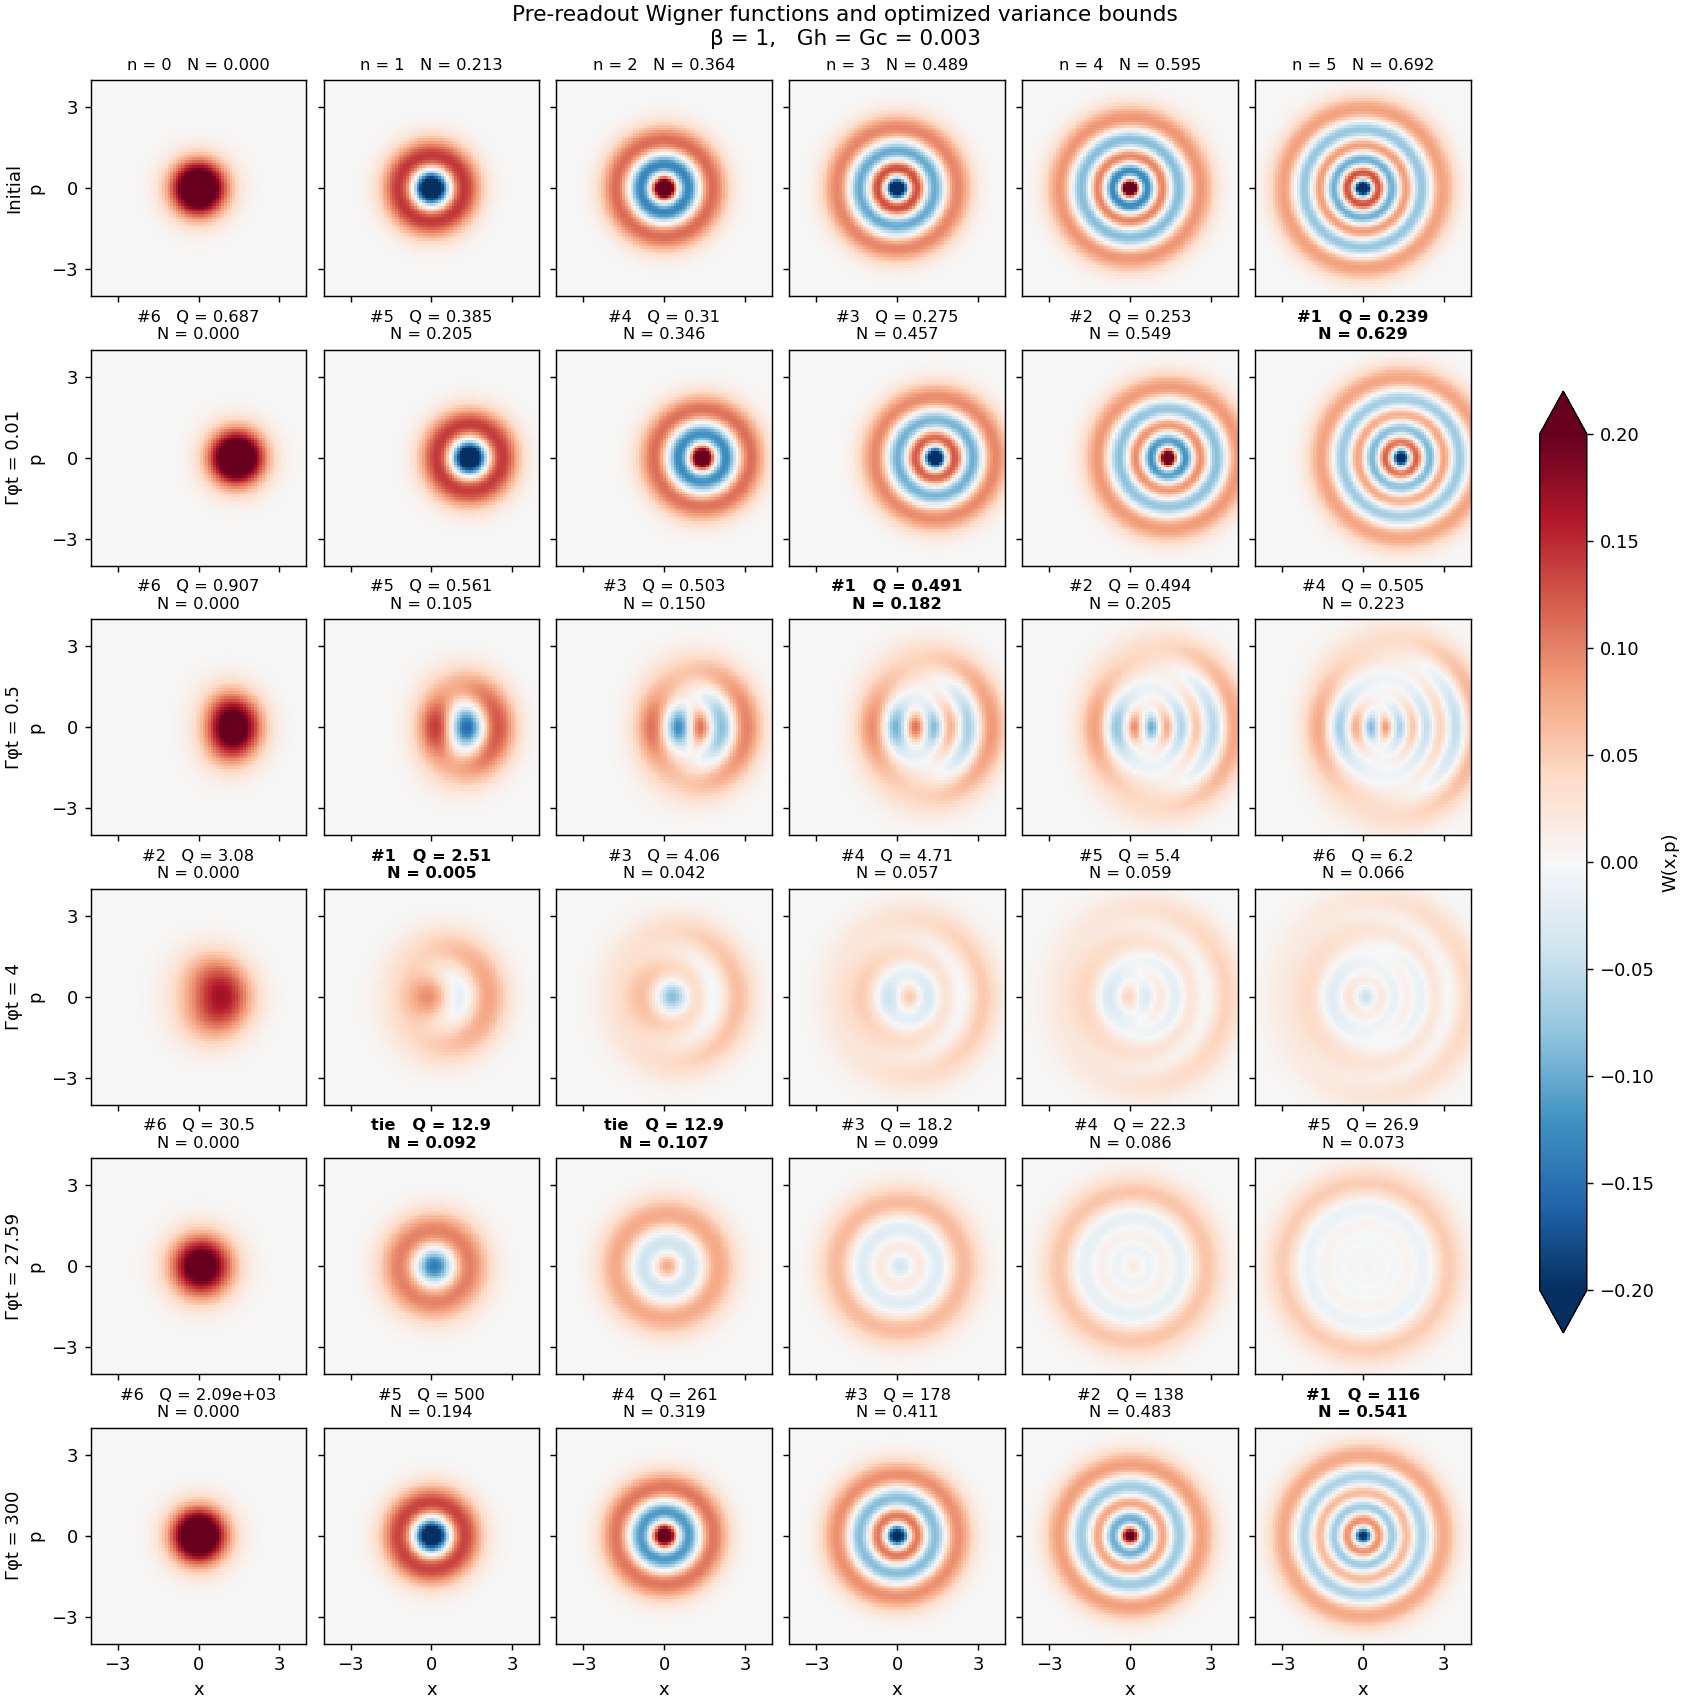

In [ ]:
function ranked_wigner()
    h = first(rank_h)
    grid = collect(-6.:.1:6.)
    basis = QO.FockBasis(rank_d-1)
    root = first(rank_roots)
    crossing = (root.lo+root.hi)/2
    marks = [0.01,0.50,4.,crossing,300.]
    fig,axes = subplots(1+length(marks),length(rank_ns),sharex=true,sharey=true,
                        figsize=(13,13.1),constrained_layout=true)
    image = nothing
    for row in 1:(1+length(marks))
        initial = row == 1
        states = initial ? (rho=[psi*psi' for psi in rank_psis],q=Float64[]) :
                           rank_states(marks[row-1],h)
        ranks = invperm(sortperm(states.q))
        for (j,n) in enumerate(rank_ns)
            ax = axes[row,j]
            W = QO.wigner(QO.DenseOperator(basis,complex.(states.rho[j])),grid,grid)
            neg = sum(max.(-W,0))*(grid[2]-grid[1])^2
            image = ax.pcolormesh(grid,grid,permutedims(W),shading="nearest",cmap="RdBu_r",vmin=-.2,vmax=.2)
            ax.set(aspect="equal",xlim=(-4,4),ylim=(-4,4),xticks=[-3,0,3],yticks=[-3,0,3])
            title = initial ? @sprintf("n = %d   N = %.3f",n,neg) :
                              @sprintf("#%d   Q = %.3g\nN = %.3f",ranks[j],states.q[j],neg)
            tied = !initial && marks[row-1]==crossing && n in (root.left,root.right)
            if tied
                title = @sprintf("tie   Q = %.3g\nN = %.3f",states.q[j],neg)
            end
            ax.set_title(title,fontsize=9,fontweight=(!initial && (ranks[j]==1 || tied) ? "bold" : "normal"))
            j==1 && ax.set_ylabel(initial ? "Initial\np" : @sprintf("Γφt = %.4g\np", marks[row-1]))
            row==1+length(marks) && ax.set_xlabel("x")
        end
    end
    fig.colorbar(image,ax=vec(axes),extend="both",shrink=.6,label="W(x,p)")
    fig.suptitle("Pre-readout Wigner functions and optimized variance bounds\nβ = 1,   Gh = Gc = 0.003")
    fig
end
wigner_figure = ranked_wigner()
display(wigner_figure)
close(wigner_figure);


On P7's three original reference points ($G_\phi=0.01,4,300$), the winning sequence is **5 → 1 → 5** among all six candidates. Restricting the ranking to P7's five displayed preparations gives **4 → 1 → 4**. A check with P7's original 61 levels, time steps and readout grid gave the same winners. The largest relative change in the individual optimized bounds at these three points was 0.18%.

The first upward switch occurs near **27.59** on the $h=0.003$ cut and **29.60** on the $h=0.01$ cut. Both are numerical crossings of optimized variance bounds. The center and negativity of a Wigner function can vary smoothly through either crossing.

A rigid displacement translates the rings and leaves their integrated negative weight unchanged. Tracking negativity alongside the centroid therefore tests whether noise has washed out the Fock fringes. A positive value witnesses nonclassical motion. The optimized QCRB determines which state gives the better sensor.